# Model 3: Random Forest
**Dataset:** Plant Disease Recognition (Healthy / Powdery / Rust)

**Category:** Classification

## Model suitability
Random Forest is an ensemble of decision trees. It handles mixed, correlated features, needs little scaling, is robust
to overfitting through averaging, and gives feature importances. That makes it a good tree-based contrast to the margin-based SVM.

## Implementation details
`sklearn.ensemble.RandomForestClassifier`, `random_state=42`. Same two feature sets as the SVM
(pixels + PCA inside a pipeline, and the 512-value colour histogram).

## Parameter tuning method
Manual variation of `n_estimators`, `max_depth` and feature set, then `GridSearchCV` (5-fold) over
`n_estimators`, `max_depth` and `min_samples_split`.

## Evaluation metric & validation method
Accuracy, per-class precision/recall/F1 and a confusion matrix. Selection by 5-fold CV accuracy on Train;
Validation and Test accuracy reported for the comparison.

In [1]:
# ---- Configuration (paths are relative to the notebooks/ folder) ----
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2
warnings.filterwarnings('ignore')

DATA_ROOT = '../data/raw'      # folder that contains Train/, Validation/ and Test/
SPLITS = {s: os.path.join(DATA_ROOT, s, s) for s in ['Train', 'Validation', 'Test']}  # dataset is nested: Train/Train/...
RESULTS = '../results'
os.makedirs(f'{RESULTS}/eda_visualizations', exist_ok=True)
os.makedirs(f'{RESULTS}/outputs', exist_ok=True)

CLASS_NAMES = sorted(d for d in os.listdir(SPLITS['Train']) if os.path.isdir(os.path.join(SPLITS['Train'], d)))
print('Classes:', CLASS_NAMES)
for s, p in SPLITS.items():
    print(s, {c: len(os.listdir(os.path.join(p, c))) for c in CLASS_NAMES})

Classes: ['Healthy', 'Powdery', 'Rust']
Train {'Healthy': 458, 'Powdery': 430, 'Rust': 434}
Validation {'Healthy': 20, 'Powdery': 20, 'Rust': 20}
Test {'Healthy': 50, 'Powdery': 50, 'Rust': 50}


In [2]:
# Helper: every notebook appends its results to one shared CSV (used later for the group comparison)
def log_result(model, variety, val_acc=None, test_acc=None, notes=''):
    path = f'{RESULTS}/outputs/model_results.csv'
    cols = ['model', 'variety', 'val_accuracy', 'test_accuracy', 'notes']
    df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame(columns=cols)
    df = df[~((df['model'] == model) & (df['variety'] == variety))].reset_index(drop=True)
    df.loc[len(df)] = [model, variety, val_acc, test_acc, notes]
    df.to_csv(path, index=False)

In [3]:
# ---- Flat features for classical ML (same preprocessing as the group pipeline) ----
#   pixels    : 64x64x3 image flattened and scaled to 0-1  (12,288 values)
#   histogram : 8x8x8 RGB colour histogram               (512 values)
def hist_feat(img):
    h = cv2.calcHist([img], [0, 1, 2], None, [8, 8, 8], [0, 256] * 3)
    return cv2.normalize(h, h).flatten()

def build_features(split, flat_size=64):
    Xp, Xh, y = [], [], []
    for idx, c in enumerate(CLASS_NAMES):
        folder = os.path.join(SPLITS[split], c)
        for f in sorted(os.listdir(folder)):
            if not f.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue
            try:
                img = np.array(Image.open(os.path.join(folder, f)).convert('RGB').resize((128, 128)))
            except Exception:
                continue                      # skip unreadable files
            Xh.append(hist_feat(img))
            Xp.append(cv2.resize(img, (flat_size, flat_size)).flatten() / 255.0)
            y.append(idx)
    return np.array(Xp, dtype='float32'), np.array(Xh, dtype='float32'), np.array(y)

CACHE = f'{RESULTS}/outputs/plant_features.npz'      # built once, reused by every notebook
keys = ['Xp_tr', 'Xh_tr', 'y_tr', 'Xp_va', 'Xh_va', 'y_va', 'Xp_te', 'Xh_te', 'y_te']
if os.path.exists(CACHE):
    d = np.load(CACHE)
    Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te = [d[k] for k in keys]
else:
    Xp_tr, Xh_tr, y_tr = build_features('Train')
    Xp_va, Xh_va, y_va = build_features('Validation')
    Xp_te, Xh_te, y_te = build_features('Test')
    np.savez_compressed(CACHE, **dict(zip(keys, [Xp_tr, Xh_tr, y_tr, Xp_va, Xh_va, y_va, Xp_te, Xh_te, y_te])))
print('Train', Xp_tr.shape, Xh_tr.shape, '| Val', Xp_va.shape, '| Test', Xp_te.shape)

Train (1322, 12288) (1322, 512) | Val (60, 12288) | Test (150, 12288)


In [4]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
import seaborn as sns

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def show_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title); plt.tight_layout()
    plt.savefig(f'{RESULTS}/eda_visualizations/{fname}', dpi=200)
    plt.show()

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
N_PCA = 100
DATA = {'pixels+PCA': (Xp_tr, Xp_va, Xp_te), 'histogram': (Xh_tr, Xh_va, Xh_te)}

def make_pipe(feats, n_estimators=100, max_depth=None, min_samples_split=2):
    steps = [('pca', PCA(N_PCA, random_state=42))] if feats == 'pixels+PCA' else []
    steps.append(('rf', RandomForestClassifier(n_estimators=n_estimators, max_depth=max_depth,
                                               min_samples_split=min_samples_split,
                                               random_state=42, n_jobs=-1)))
    return Pipeline(steps)

varieties = [
    ('V1 100 trees, no depth limit',  'pixels+PCA', dict(n_estimators=100)),
    ('V2 300 trees, depth 20',        'pixels+PCA', dict(n_estimators=300, max_depth=20)),
    ('V3 300 trees, depth 20',        'histogram',  dict(n_estimators=300, max_depth=20)),
    ('V4 50 trees, no depth limit',   'histogram',  dict(n_estimators=50)),
]
rows, fitted = [], {}
for name, feats, params in varieties:
    Xtr, Xva, Xte = DATA[feats]
    pipe = make_pipe(feats, **params)
    cv_acc = cross_val_score(pipe, Xtr, y_tr, cv=cv).mean()
    pipe.fit(Xtr, y_tr)
    pred_te = pipe.predict(Xte)
    rows.append([name, feats, cv_acc, accuracy_score(y_va, pipe.predict(Xva)),
                 accuracy_score(y_te, pred_te), f1_score(y_te, pred_te, average='macro')])
    fitted[name] = (pipe, feats)
comparison = pd.DataFrame(rows, columns=['Variety', 'Features', 'CV acc (Train)', 'Val acc',
                                         'Test acc', 'Test macro-F1']).round(3)
comparison

,Variety,Features,CV acc (Train),Val acc,Test acc,Test macro-F1
0,"V1 100 trees, no depth limit",pixels+PCA,0.782,0.717,0.613,0.608
1,"V2 300 trees, depth 20",pixels+PCA,0.790,0.717,0.660,0.656
2,"V3 300 trees, depth 20",histogram,0.921,0.933,0.900,0.900
3,"V4 50 trees, no depth limit",histogram,0.925,0.933,0.900,0.900


In [10]:
# V5: GridSearchCV on the better feature set
best_feats = comparison.sort_values('CV acc (Train)', ascending=False).iloc[0]['Features']
print('Feature set used for grid search:', best_feats)
grid = GridSearchCV(make_pipe(best_feats),
                    {'rf__n_estimators': [100, 300, 500], 'rf__max_depth': [None, 10, 20],
                     'rf__min_samples_split': [2, 5]},
                    cv=cv, n_jobs=1)
Xtr, Xva, Xte = DATA[best_feats]
grid.fit(Xtr, y_tr)
print('Best params:', grid.best_params_, '| best CV acc:', round(grid.best_score_, 3))
v5 = f"V5 grid search ({best_feats})"
pred_te = grid.predict(Xte)
comparison.loc[len(comparison)] = [v5, best_feats, round(grid.best_score_, 3),
                                   round(accuracy_score(y_va, grid.predict(Xva)), 3),
                                   round(accuracy_score(y_te, pred_te), 3),
                                   round(f1_score(y_te, pred_te, average='macro'), 3)]
fitted[v5] = (grid.best_estimator_, best_feats)
comparison

Feature set used for grid search: histogram
Best params: {'rf__max_depth': 20, 'rf__min_samples_split': 2, 'rf__n_estimators': 100} | best CV acc: 0.924


,Variety,Features,CV acc (Train),Val acc,Test acc,Test macro-F1
0,"V1 100 trees, no depth limit",pixels+PCA,0.782,0.717,0.613,0.608
1,"V2 300 trees, depth 20",pixels+PCA,0.790,0.717,0.660,0.656
2,"V3 300 trees, depth 20",histogram,0.921,0.933,0.900,0.900
3,"V4 50 trees, no depth limit",histogram,0.925,0.933,0.900,0.900
4,V5 grid search (histogram),histogram,0.924,0.933,0.900,0.901


## Comparison across varieties
Use the table above. Compare number of trees, depth limit, feature set, and whether grid search helped.

Selected: V4 50 trees, no depth limit
              precision    recall  f1-score   support

     Healthy       0.83      0.90      0.87        50
     Powdery       0.91      0.86      0.89        50
        Rust       0.96      0.94      0.95        50

    accuracy                           0.90       150
   macro avg       0.90      0.90      0.90       150
weighted avg       0.90      0.90      0.90       150



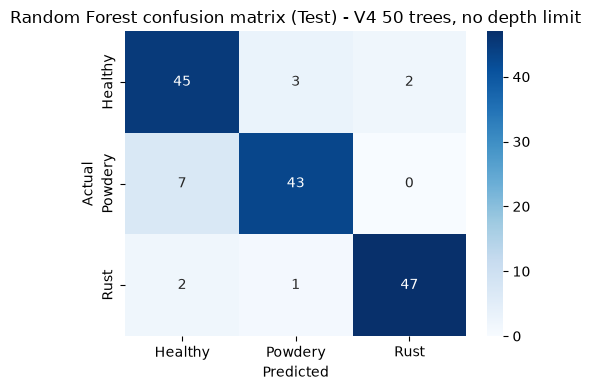

In [11]:
best_name = comparison.sort_values('CV acc (Train)', ascending=False).iloc[0]['Variety']
best_pipe, best_f = fitted[best_name]
y_pred = best_pipe.predict(DATA[best_f][2])
print('Selected:', best_name)
print(classification_report(y_te, y_pred, target_names=CLASS_NAMES))
show_confusion(y_te, y_pred, f'Random Forest confusion matrix (Test) - {best_name}', 'rf_confusion_matrix.png')
for _, r in comparison.iterrows():
    log_result('Random Forest', r['Variety'], r['Val acc'], r['Test acc'], f"cv={r['CV acc (Train)']}")

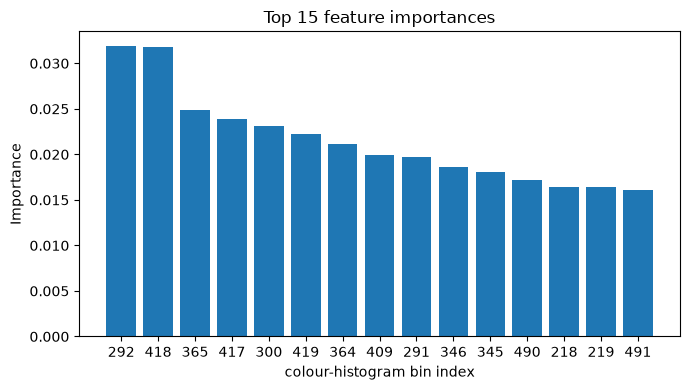

In [12]:
# Feature importance of the selected model (top 15)
rf = best_pipe.named_steps['rf']
imp = rf.feature_importances_
top = np.argsort(imp)[::-1][:15]
label = 'colour-histogram bin' if best_f == 'histogram' else 'principal component'
plt.figure(figsize=(7, 4))
plt.bar([str(i) for i in top], imp[top])
plt.xlabel(label + ' index'); plt.ylabel('Importance'); plt.title('Top 15 feature importances')
plt.tight_layout(); plt.savefig(f'{RESULTS}/eda_visualizations/rf_feature_importance.png', dpi=200); plt.show()

## Conclusion 

**Variety Selected and Why:**
The **V4 50 trees, no depth limit** model was selected because it achieved the highest cross-validation accuracy on the training set at 0.925. Interestingly, this simpler configuration slightly outperformed the V5 Grid Search (0.924 CV accuracy) and achieved the exact same test accuracy (0.900) and test macro-F1 (0.900) as the grid search model.

**Feature Set Comparison & Hyperparameters:**
The 512-value RGB color histogram drastically outperformed the PCA-reduced pixel features. The baseline 100-tree model on PCA pixels (V1) yielded a test accuracy of just 0.613, whereas a 50-tree model on the histogram features (V4) achieved a 0.900 test accuracy. Because the histogram features were so strongly predictive, varying the number of trees and the maximum depth (as seen in V3, V4, and V5) had almost no impact on the final test accuracy (all scored 0.900). 

**Class Confusion Analysis:**
According to the classification report, the Random Forest model was exceptionally good at identifying the "Rust" class, achieving a 0.96 precision and 0.94 recall. The model experienced the most confusion between the "Healthy" and "Powdery" classes. "Powdery" had the lowest recall (0.86), while "Healthy" had the lowest precision (0.83). This indicates that the model occasionally falsely predicted Powdery mildew images as Healthy, likely because early-stage powdery mildew might not alter the overall color histogram of the leaf enough to separate it from a healthy green baseline in a decision tree split.